# Exercise: what's on the menu?

In this exercise you'll find out how the amount and the type of food change how fast *E. coli* grows.

In [1]:
setLanguage('en')   % language of the messages below

Language: English


In [2]:
model = loadEcoli();

Model loaded: E. coli core model with 95 reactions, 72 metabolites and 137 genes.


## More sugar, faster growth?

Each food has an **exchange reaction** whose ID starts with `EX_`. Glucose is `EX_glc__D_e`. With `changeRxnBounds` you set how much of it the cell may take up. The amount is negative, because taking up means the substance *leaves* the surroundings.

The cell below tries glucose amounts from 0 to 20. Run it.

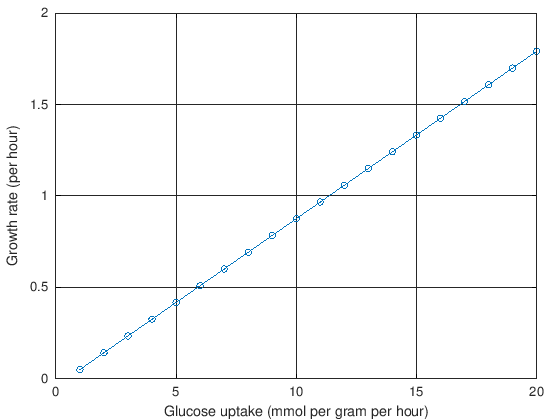

In [3]:
glucose = 0:1:20;
growth = zeros(size(glucose));
for i = 1:numel(glucose)
  m = changeRxnBounds(model, 'EX_glc__D_e', -glucose(i), 'l');   % allow this much glucose
  s = optimizeCbModel(m);
  growth(i) = s.f;
end
plot(glucose, growth, 'o-', 'linewidth', 2)
xlabel('Glucose uptake (mmol per gram per hour)')
ylabel('Growth rate (per hour)')
grid on

**Question 1:** What shape does the line have? What happens to the growth rate if you double the glucose?

✅ **Answer:** A **straight line**: double the glucose gives double the growth (5 → 0.42, 10 → 0.87, 20 → 1.79 per hour). With very little glucose (below about half a unit) there is no growth, because the cell first needs energy just to stay alive (*maintenance*). With no glucose at all the model finds no solution, so the point at 0 is missing. In a real cell the line would level off, because the transporters that bring sugar into the cell can only work so fast.

## Other foods

*E. coli* can also live on other foods. In the cell below, glucose is switched off (0) and the cell gets 10 units of **acetate** (`EX_ac_e`) instead.

In [4]:
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');   % no glucose
m = changeRxnBounds(m, 'EX_ac_e', -10, 'l');          % 10 units of acetate
showGrowth(m);

Growth rate: 0.173 per hour (the cells double every 240 minutes).


Now it's your turn. Try **fructose** (fruit sugar, `EX_fru_e`) and **succinate** (`EX_succ_e`). Replace `___` with the ID of the food.

| Food | ID | Growth rate (per hour) |
|---|---|---|
| glucose | `EX_glc__D_e` | 0.874 |
| acetate | `EX_ac_e` | |
| fructose | `EX_fru_e` | |
| succinate | `EX_succ_e` | |

*Double-click the table to fill in your results.*

In [5]:
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');   % no glucose
m = changeRxnBounds(m, 'EX_fru_e', -10, 'l');         % 10 units of another food
showGrowth(m);
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');
m = changeRxnBounds(m, 'EX_succ_e', -10, 'l');
showGrowth(m);

Growth rate: 0.874 per hour (the cells double every 48 minutes).


Growth rate: 0.398 per hour (the cells double every 105 minutes).


**Question 2:** Which food is best for *E. coli*, and which is worst? Glucose and fructose have **6** carbon atoms per molecule, succinate has **4** and acetate only **2**. Can you explain the results with that?

✅ **Answer:** Glucose and fructose: 0.874, succinate: 0.398, acetate: 0.173 per hour. Glucose and fructose are equally good. The cell gets the same amount of material and energy from them, because fructose is converted into the same intermediate products. The fewer carbon atoms a molecule has, the less building material and energy the cell gets from each molecule, so it grows more slowly.

**Extra:** Can *E. coli* live on acetate **without oxygen**? Try it with `setMedium(m, 0, 0)` after giving it acetate.

In [6]:
m = changeRxnBounds(model, 'EX_ac_e', -10, 'l');
m = setMedium(m, 0, 0);   % no glucose, no oxygen
showGrowth(m);

Food: glucose uptake up to 0, oxygen uptake up to 0 (mmol per gram per hour).


No solution: the model cannot run under these conditions.


✅ **Answer:** No. Acetate is itself a waste product of fermentation, so there's no energy left to get from it without oxygen. The model finds no solution at all, because the cell can't even make the energy it needs to stay alive.

**Done!** Continue with `04_exercise_knockouts.ipynb`.

<small>Model: *E. coli* core model from BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Full sources at the end of `01_tutorial_fba.ipynb`.</small>